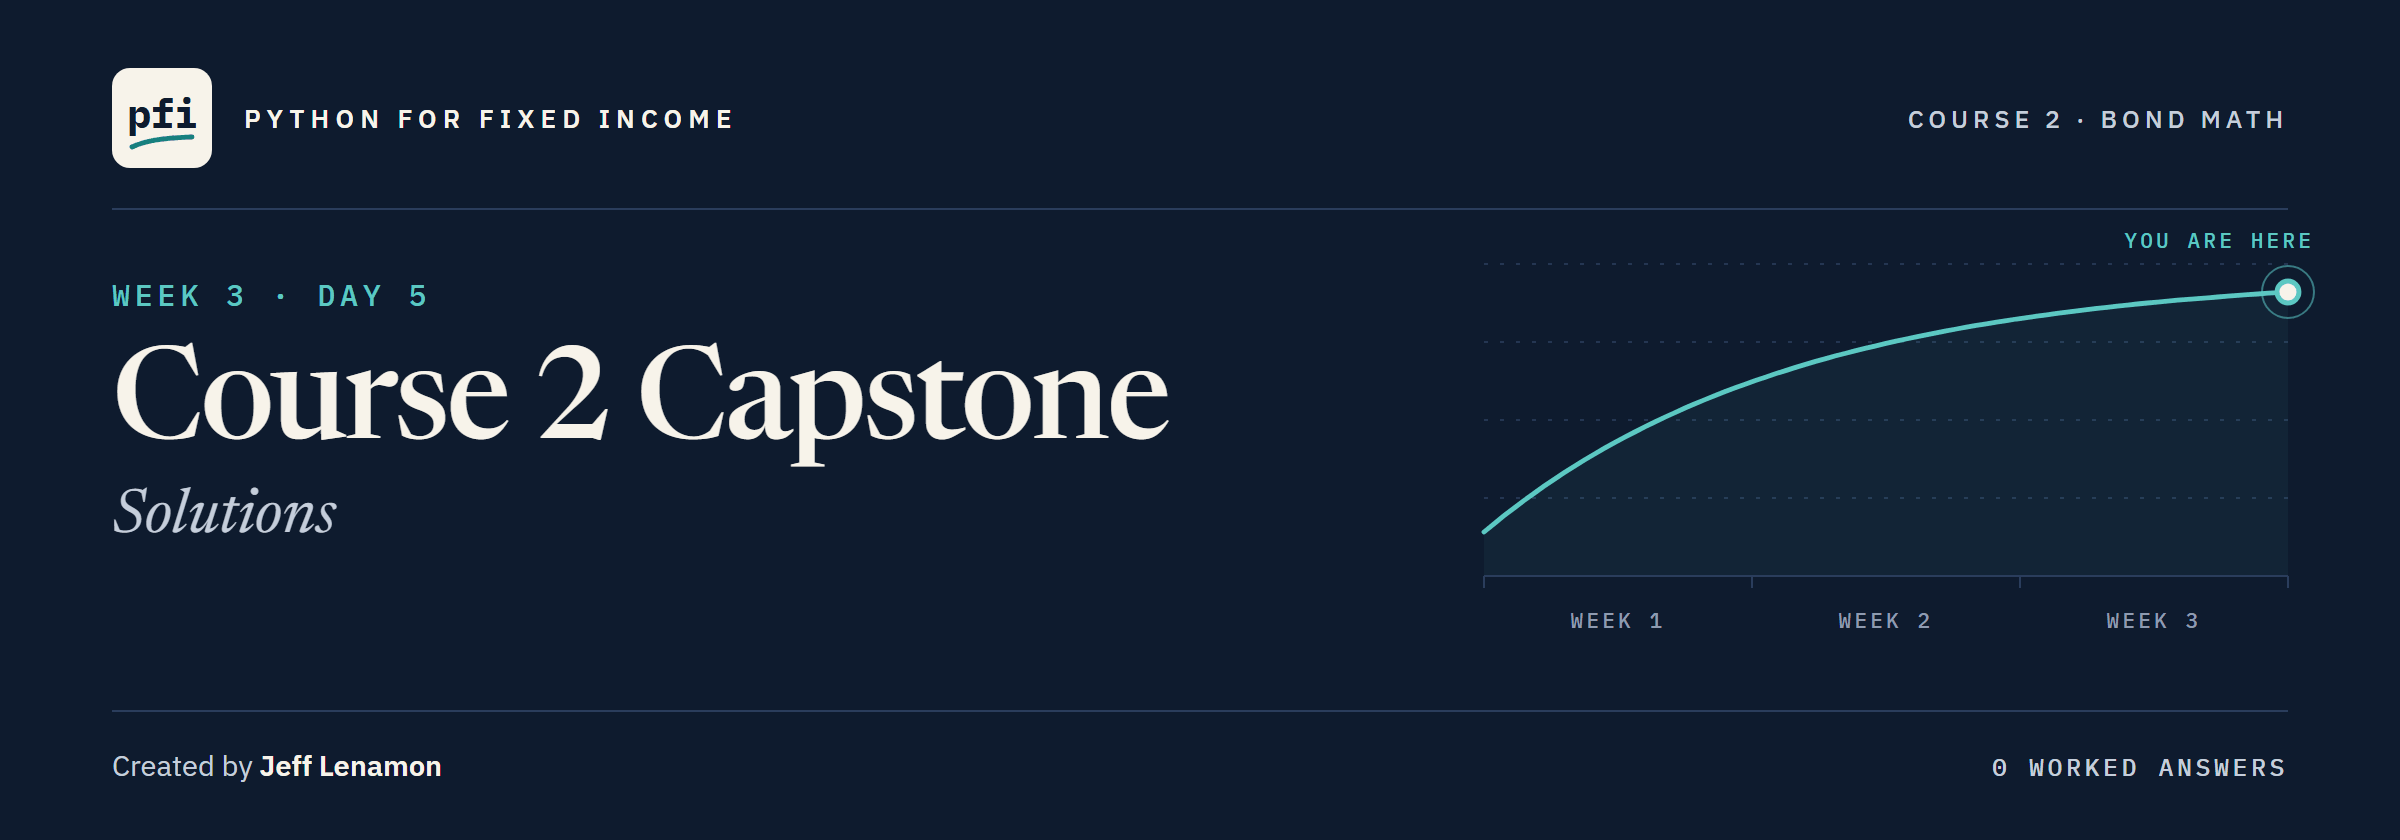

# Course 2 Capstone: Solutions

Week 3, Day 5. The worked version of the capstone: every question answered with code, its output, and what the output shows. Write your own answers and your own page first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day5/course2_capstone_solutions.ipynb)

## Setup

The same cells as the capstone notebook.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 14 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(15, after=14)

Work folder pfi_course2_15_k4w7q2xr: 8 data files, the module as notebook 14 left it, 14 commits, tagged week1 and week2


In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................................                                 [100%]
40 passed in 0.50s



In [3]:
import importlib
import math
import re
from datetime import date

import bondmath
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

# the files start_day copied into the work folder; raw is the extract exactly as it arrived
raw = pd.read_csv('course2_capstone_holdings.csv')
benchmark = pd.read_csv('benchmark.csv')
ratings = pd.read_csv('ratings.csv')
curve = pd.read_csv('course2_treasury_curve.csv')
september = pd.read_csv('holdings.csv')
# the cover note's control totals
expected_bonds = 199
expected_face = 493_000_000
expected_value = 496_372_835.00


def headline(label, table):
    # the headline numbers, printed before and after every fix, as in Course 1's EDA notebook
    print(f"{label}: {len(table):,} rows | face {table['par_held'].sum():,} | "
          f"market value {table['market_value'].sum():,.2f} | "
          f"mean yield {table['yield_pct'].mean():.3f}")


print('benchmark', benchmark.shape, '| ratings', ratings.shape, '| curve', curve.shape,
      '| september', september.shape)

benchmark (821, 19) | ratings (18, 4) | curve (10, 2) | september (200, 19)


In [4]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written here
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    # a number is rounded to the places the question asks for, so 7 and 7.0 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + '|' + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have ' + str(answer))

## 1 The File and Its Note

### 1.1 Rows, Columns, and a Working Copy

In [5]:
# shape is a pair: (rows, columns)
answer_1_1 = raw.shape
# book is the working copy; raw is not changed again
book = raw.copy()
print(answer_1_1)

(201, 19)


In [6]:
check('Question 1.1', answer_1_1, '27e687cbc05d')

Question 1.1: correct


201 rows and 19 columns, where the cover note says 199 bonds: two rows too many before a value is read.

### 1.2 The File Less Its Note

In [7]:
headline('As received', raw)
# each total less the cover note's
answer_1_2 = raw['par_held'].sum() - expected_face
print('rows:', len(raw) - expected_bonds, '| face:', f'{answer_1_2:,}')
print(f"market value: {raw['market_value'].sum() - expected_value:,.2f}")

As received: 201 rows | face 499,000,000 | market value 502,631,442.50 | mean yield 6.006
rows: 2 | face: 6,000,000
market value: 6,258,607.50


In [8]:
check('Question 1.2', answer_1_2, '6a6b09d5d958', places=0)

Question 1.2: correct


2 rows, 6,000,000 dollars of face, and 6,258,607.50 dollars of market value more than the note.
All three gaps point the same way, as extra rows would.

## 2 Test the Inputs

### 2.1 Rule 1: One Row for Each Bond

In [9]:
# duplicated() marks a row that matches an earlier row in every column
copies = book.duplicated()
answer_2_1 = copies.sum()
print(answer_2_1, f"{book.loc[copies, 'par_held'].sum():,}",
      f"{book.loc[copies, 'market_value'].sum():,.2f}")
# keep=False marks the original as well as its copy
book.loc[book.duplicated(keep=False), ['cusip', 'ticker', 'maturity', 'par_held', 'market_value']]

2 6,000,000 6,258,607.50


,cusip,ticker,maturity,par_held,market_value
50,99089LAG4,ELVE,2031-08-26,4250000,4549540.0
51,99089LAG4,ELVE,2031-08-26,4250000,4549540.0
52,99089LAF6,ELVE,2038-05-08,1750000,1709067.5
53,99089LAF6,ELVE,2038-05-08,1750000,1709067.5


In [10]:
check('Question 2.1', answer_2_1, 'aadc199a297c', places=0)

Question 2.1: correct


2 rows are exact copies, ELVE `99089LAG4` and `99089LAF6`, each directly below its original.
They carry 6,000,000 dollars of face and 6,258,607.50 of value: 1.2's gaps, to the cent.

### 2.2 Rule 2: The Maturity

In [11]:
# text written year-month-day sorts in date order, so <= compares dates
matured = book['maturity'] <= book['as_of_date']
answer_2_2 = matured.sum()
book.loc[matured, ['cusip', 'ticker', 'coupon', 'maturity', 'duration']]

,cusip,ticker,coupon,maturity,duration
38,99030EAE5,DRAE,4.125,2021-07-10,4.09


In [12]:
check('Question 2.2', answer_2_2, '638d0c69ab0f', places=0)

Question 2.2: correct


DRAE `99030EAE5` matured on 2021-07-10 yet carries a duration of 4.09 years: the maturity is the wrong column, and `coupon_dates` would stop on it.

### 2.3 Rule 3: Missing Numbers

In [13]:
missing = book.isna().sum()
answer_2_3 = missing.sum()
print(missing[missing > 0])
# a row with a gap has a count of missing cells above 0 across the row (axis=1)
book.loc[book.isna().sum(axis=1) > 0, ['cusip', 'ticker', 'coupon', 'maturity', 'price',
                                       'yield_pct']]

price        2
yield_pct    2
dtype: int64


,cusip,ticker,coupon,maturity,price,yield_pct
120,99008IAA2,OSMC,4.625,2034-11-22,94.508,NaN
127,99003DAE0,PLWK,5.125,2035-06-11,96.417,NaN
171,99091NAA9,VRAN,4.125,2035-09-03,NaN,5.270
191,99108EAE2,XANH,4.625,2036-07-27,NaN,5.456


In [14]:
check('Question 2.3', answer_2_3, '99bce1a159e6', places=0)

Question 2.3: correct


4 cells: 2 yields (OSMC, PLWK) and 2 prices (VRAN, XANH), in 4 rows.
Each row still holds the other number of the pair, so the module gives the blank back; dropping the rows would drop bonds the desk owns.

### 2.4 Rule 4: Units

In [15]:
print(book[['coupon', 'yield_pct']].describe().round(3))
answer_2_4a = (book['coupon'] < 1).sum()
answer_2_4b = (book['yield_pct'] < 1).sum()
small = (book['coupon'] < 1) | (book['yield_pct'] < 1)
book.loc[small, ['cusip', 'ticker', 'coupon', 'yield_pct', 'price', 'accrued']]

        coupon  yield_pct
count  201.000    199.000
mean     5.866      6.006
std      1.736      2.068
min      0.041      0.051
25%      4.750      5.026
50%      5.625      5.561
75%      6.750      6.404
max     11.000     18.345


,cusip,ticker,coupon,yield_pct,price,accrued
5,99126WAE0,BEZR,0.04125,4.49900,99.078,1.535
62,99021VAC2,FESA,6.00000,0.05256,105.946,2.983
117,99054CAG5,NEVX,3.87500,0.05968,75.065,1.550
134,99106CAH1,QUEX,0.04125,4.46500,99.171,1.661
197,99062KAE2,ZEPL,4.75000,0.05088,97.426,1.333


In [16]:
check('Question 2.4 coupons', answer_2_4a, '08c62009b4d4', places=0)
check('Question 2.4 yields', answer_2_4b, '9a54f14f80a8', places=0)

Question 2.4 coupons: correct
Question 2.4 yields: correct


2 coupons and 3 yields are about a hundredth of their neighbours: BEZR and QUEX at 0.04125, FESA, NEVX, and ZEPL near 0.05.
Each sits beside a price and an accrued that only the larger number gives.

### 2.5 Rules 5 and 7

In [17]:
# market value from three other columns; a blank price leaves a blank gap, never counted
gap = (book['par_held'] * (book['price'] + book['accrued']) / 100 - book['market_value']).abs()
answer_2_5a = (gap > 0.005).sum()
print('tested', gap.notna().sum(), '| beyond half a cent', answer_2_5a)
# one mask per test of rule 7; True marks a row that breaks it
tests = [~book['cusip'].str.fullmatch(r'[A-Z0-9]{9}'), ~book['rating'].isin(ratings['rating']),
         book['par_held'] <= 0, book['par_held'] > book['amount_outstanding'],
         book['spread_duration'] <= 0, book['price_date'] != book['as_of_date']]
answer_2_5b = sum([test.sum() for test in tests])
print('rule 7 breaks:', answer_2_5b)

tested 199 | beyond half a cent 6
rule 7 breaks: 0


In [18]:
check('Question 2.5 tie-out', answer_2_5a, '51b7fe7570fc', places=0)
check('Question 2.5 rule 7', answer_2_5b, 'd8983dbd80c1', places=0)

Question 2.5 tie-out: correct
Question 2.5 rule 7: correct


199 rows tested, the two blank prices left out, and 6 do not tie out: the rule says the columns disagree, not which one is wrong.
Rule 7 and the price dates find nothing, and a clean result goes in the page.

## 3 Fix the Inputs

### 3.1 Copies, Maturity, and Units

**Decision 1.** Remove the 2 copies, keeping the first of each.

Evidence: they match an earlier row in all 19 columns and carry exactly the excess over the cover note.

In [19]:
headline('Before', book)
# drop_duplicates() keeps the first of each; reset_index(drop=True) renumbers from 0
book = book.drop_duplicates().reset_index(drop=True)
headline('After', book)

Before: 201 rows | face 499,000,000 | market value 502,631,442.50 | mean yield 6.006
After: 199 rows | face 493,000,000 | market value 496,372,835.00 | mean yield 6.010


**Decision 2.** Replace the 2021 maturity with the benchmark's.

Evidence: the benchmark lists the same CUSIP with the same ticker and coupon, maturing ten years later, which fits a duration of 4.09 years.

In [20]:
matured = book['maturity'] <= book['as_of_date']
cusip = book.loc[matured, 'cusip'].iloc[0]
listed = benchmark[benchmark['cusip'] == cusip]
print(listed[['cusip', 'ticker', 'coupon', 'maturity']])
assert listed['ticker'].iloc[0] == book.loc[matured, 'ticker'].iloc[0], 'another bond'
headline('Before', book)
book.loc[matured, 'maturity'] = listed['maturity'].iloc[0]
headline('After', book)
answer_3_1b = book.loc[book['cusip'] == cusip, 'maturity'].iloc[0]
print(cusip, answer_3_1b)

         cusip ticker  coupon    maturity
156  99030EAE5   DRAE   4.125  2031-07-10
Before: 199 rows | face 493,000,000 | market value 496,372,835.00 | mean yield 6.010
After: 199 rows | face 493,000,000 | market value 496,372,835.00 | mean yield 6.010
99030EAE5 2031-07-10


**Decision 3.** Multiply the 2 coupons and 3 yields below 1 percent by 100, to 3 decimals.

Evidence: each is a hundredth of a value in line with its row; section 4 shows each row reprices.

In [21]:
headline('Before', book)
for column in ['coupon', 'yield_pct']:
    decimal = book[column] < 1
    # three decimals, like the rest of the column
    book.loc[decimal, column] = (book.loc[decimal, column] * 100).round(3)
headline('After', book)
answer_3_1a = book['par_held'].sum()
answer_3_1c = book['coupon'].mean()
print(book['coupon'].min(), book['yield_pct'].min())

Before: 199 rows | face 493,000,000 | market value 496,372,835.00 | mean yield 6.010
After: 199 rows | face 493,000,000 | market value 496,372,835.00 | mean yield 6.092
3.25 4.102


In [22]:
check('Question 3.1 face', answer_3_1a, 'fd62f80a9c8b', places=0)
check('Question 3.1 maturity', answer_3_1b, '2755386de0d9')
check('Question 3.1 mean coupon', answer_3_1c, '59506b3d5415', places=3)

Question 3.1 face: correct
Question 3.1 maturity: correct
Question 3.1 mean coupon: correct


The control totals tie once the copies go: 199 bonds, 493,000,000 dollars of face, 496,372,835.00 of value.
The maturity and unit fixes move no total, yet the mean yield rises from 6.010 to 6.092 percent: totals cannot see these errors.

### 3.2 Fill the Blanks

**Decision 4.** Fill the 2 blank yields from their prices and the 2 blank prices from their yields, with `yield_to_maturity` and `price`, to 3 decimals.

Evidence: given the terms, price and yield are one number seen two ways.

In [23]:
settlements = [date.fromisoformat(text) for text in book['as_of_date']]
maturities = [date.fromisoformat(text) for text in book['maturity']]
blank_yield = book['yield_pct'].isna()
blank_price = book['price'].isna()
headline('Before', book)
# each blank from the other number of its pair; the filter keeps only the blank rows
solved_yields = [round(bondmath.yield_to_maturity(s, m, c, p), 3) for s, m, c, p, blank
                 in zip(settlements, maturities, book['coupon'], book['price'], blank_yield)
                 if blank]
solved_prices = [round(bondmath.price(s, m, c, y), 3) for s, m, c, y, blank
                 in zip(settlements, maturities, book['coupon'], book['yield_pct'], blank_price)
                 if blank]
book.loc[blank_yield, 'yield_pct'] = solved_yields
book.loc[blank_price, 'price'] = solved_prices
headline('After', book)
answer_3_2a = sum(solved_yields)
answer_3_2b = sum(solved_prices)
print(solved_yields, solved_prices, book[raw.columns].isna().sum().sum())

Before: 199 rows | face 493,000,000 | market value 496,372,835.00 | mean yield 6.092
After: 199 rows | face 493,000,000 | market value 496,372,835.00 | mean yield 6.087
[5.484, 5.66] [92.043, 93.818] 0


In [24]:
check('Question 3.2 yields', answer_3_2a, 'c0e61eb6bd31', places=3)
check('Question 3.2 prices', answer_3_2b, '8db14052fa4d', places=3)

Question 3.2 yields: correct
Question 3.2 prices: correct


Yields of 5.484 and 5.66 percent and prices of 92.043 and 93.818, summing to 11.144 and 185.861; no cell is blank.

## 4 Reprice Every Bond

### 4.1 Accrued Interest

In [25]:
# notebook 10's tolerances
ROUNDED_3 = 0.0005 + 1e-9
YIELD_FROM_ROUNDED_PRICE = 0.001
# each bond's four inputs in one tuple, as in notebook 14
bonds = list(zip(settlements, maturities, book['coupon'], book['yield_pct']))
book['accrued_calc'] = [bondmath.accrued_interest(s, m, c) for s, m, c, y in bonds]
off = (book['accrued'] - book['accrued_calc']).abs() > ROUNDED_3
answer_4_1 = off.sum()
evidence = book.loc[off, ['cusip', 'ticker', 'coupon', 'accrued', 'accrued_calc']].copy()
# the coupon over the actual days since the last coupon, over 360
evidence['actual_360'] = [round(c * (s - bondmath.coupon_dates(s, m)[0]).days / 360, 3)
                          for (s, m, c, y), bad in zip(bonds, off) if bad]
evidence

,cusip,ticker,coupon,accrued,accrued_calc,actual_360
37,99023XAD4,DRAA,5.500,2.139,2.093056,2.139
67,99011LAC6,GALN,3.625,1.782,1.752083,1.782
142,99046UAA9,SKEN,9.500,3.035,2.981944,3.035


In [26]:
check('Question 4.1', answer_4_1, '2d66e80f087e', places=0)

Question 4.1: correct


3 rows: DRAA, GALN, and SKEN.
Each file figure equals the coupon times the actual days over 360 to the last digit: notebook 07's day counts, found in a file.

**Decision 5.** Replace the 3 accrued figures with the 30/360 accrued, to 3 decimals.

Evidence: each equals the actual/360 count exactly, and the cover note says 30/360.

In [27]:
book.loc[off, 'accrued'] = book.loc[off, 'accrued_calc'].round(3)
print(((book['accrued'] - book['accrued_calc']).abs() > ROUNDED_3).sum())

0


### 4.2 Price and Yield

In [28]:
book['price_calc'] = [bondmath.price(*bond) for bond in bonds]
off = (book['price'] - book['price_calc']).abs() > ROUNDED_3
answer_4_2a = off.sum()
evidence = book.loc[off, ['cusip', 'ticker', 'price', 'accrued', 'price_calc']].copy()
evidence['calc_plus_accrued'] = evidence['price_calc'] + evidence['accrued']
evidence.round(4)

,cusip,ticker,price,accrued,price_calc,calc_plus_accrued
108,99094QAD3,NEVE,108.955,1.354,107.6014,108.9554
163,99093PAA2,TROE,101.276,1.872,99.4044,101.2764
165,99085HAA0,TROR,99.839,0.783,99.0558,99.8388


**Decision 6.** Replace the 3 prices with price less accrued, to 3 decimals.

Evidence: `price_calc` plus accrued gives each file price within 0.0005, the dirty price in a clean column.

In [29]:
headline('Before', book)
book.loc[off, 'price'] = (book.loc[off, 'price'] - book.loc[off, 'accrued']).round(3)
headline('After', book)
# the yield from the price as it now stands
book['yield_calc'] = [bondmath.yield_to_maturity(s, m, c, p) for s, m, c, p
                      in zip(settlements, maturities, book['coupon'], book['price'])]
yield_gap = (book['yield_calc'] - book['yield_pct']).abs()
answer_4_2b = yield_gap.max()
print(f'largest yield gap {answer_4_2b:.6f} percent; beyond 0.001: '
      f'{(yield_gap > YIELD_FROM_ROUNDED_PRICE).sum()}')

Before: 199 rows | face 493,000,000 | market value 496,372,835.00 | mean yield 6.087
After: 199 rows | face 493,000,000 | market value 496,372,835.00 | mean yield 6.087
largest yield gap 0.000940 percent; beyond 0.001: 0


In [30]:
check('Question 4.2 prices', answer_4_2a, 'fb3188e7852d', places=0)
check('Question 4.2 yield gap', answer_4_2b, 'f965708cf248', places=4)

Question 4.2 prices: correct
Question 4.2 yield gap: correct


3 prices, NEVE, TROE, and TROR: with 4.1's three, the 6 rows that did not tie out in 2.5.
Every yield then reproduces: the largest gap is 0.00094 percent, inside notebook 10's 0.001.

### 4.3 Duration

In [31]:
book['duration_calc'] = [bondmath.modified_duration(*bond) for bond in bonds]
off = (book['duration'] - book['duration_calc']).abs() > ROUNDED_3
answer_4_3 = off.sum()
columns = ['cusip', 'ticker', 'duration', 'spread_duration', 'duration_calc']
evidence = book.loc[off, columns].copy()
evidence['macaulay'] = [bondmath.macaulay_duration(*bond) for bond, bad in zip(bonds, off) if bad]
evidence.round(4)

,cusip,ticker,duration,spread_duration,duration_calc,macaulay
10,99120QAC3,CLAL,4.207,4.111,4.1108,4.2067
182,99074WAD4,WYXA,11.582,11.125,11.1249,11.5818
197,99138IAD9,ZEPN,4.109,4.012,4.0121,4.1094


In [32]:
check('Question 4.3', answer_4_3, 'b3e709fd267c', places=0)

Question 4.3: correct


3 rows, CLAL, WYXA, and ZEPN, each holding Macaulay duration where the file means modified.
The `spread_duration` beside each is right, which is why only these rows have the two columns differ.

**Decision 7.** Replace the 3 durations with modified duration, to 3 decimals.

Evidence: each equals `macaulay_duration` within the rounding, and modified duration equals the row's own spread duration.

In [33]:
book.loc[off, 'duration'] = book.loc[off, 'duration_calc'].round(3)
print((book['duration'] != book['spread_duration']).sum())

0


### 4.4 The Two Special Bonds

In [34]:
# a maturity on the last day of its month, as notebook 06 tested with .dt.is_month_end
month_end = pd.to_datetime(book['maturity']).dt.is_month_end
i = list(month_end).index(True)
schedule = bondmath.coupon_dates(settlements[i], maturities[i])
print(book.loc[i, 'cusip'], maturities[i], schedule[0], schedule[1])
print(bondmath.days_30_360(schedule[0], settlements[i]), book.loc[i, 'accrued_calc'])
answer_4_4a = schedule[1].isoformat()

99008IYA6 2033-08-31 2026-08-31 2027-02-28
90 1.375


In [35]:
# one coupon left: coupon_dates holds the previous date and maturity
final = [len(bondmath.coupon_dates(s, m)) == 2 for s, m in zip(settlements, maturities)]
j = final.index(True)
print(book.loc[j, 'cusip'], maturities[j],
      bondmath.coupon_period_days(settlements[j], maturities[j]))
answer_4_4b = bondmath.dirty_price(*bonds[j])
print(f"dirty {answer_4_4b:.6f}, clean {book.loc[j, 'price_calc']:.6f}, "
      f"file {book.loc[j, 'price']}")

99007HYA9 2027-03-15 (75, 180, 105)
dirty 100.891143, clean 100.005727, file 100.006


In [36]:
check('Question 4.4 next coupon', answer_4_4a, 'bbed8c195fae')
check('Question 4.4 dirty price', answer_4_4b, 'c0c321eb15fc', places=6)

Question 4.4 next coupon: correct
Question 4.4 dirty price: correct


OSMC `99008IYA6` matures 2033-08-31, so every coupon falls on a month end: previous 2026-08-31, next 2027-02-28, 90 days accrued on 30/360, and an accrued of 1.375, the file's figure.
TRNW `99007HYA9` has one coupon left: A = 75, E = 180, DSC = 105, and simple interest gives a dirty price of 100.891143 and a clean 100.005727, the file's 100.006.
In Excel, `COUPPCD` and `COUPNCD` return 2026-08-31 and 2027-02-28, `PRICE` 98.8825959140739 for the month-end bond, `COUPNUM` 1, and `PRICE` 100.00572668808117 for the final-period bond, each equal to `bondmath` within 1e-6.

### 4.5 Dirty Price, DV01, and Convexity

In [37]:
book['dirty_price'] = [bondmath.dirty_price(*bond) for bond in bonds]
book['dv01'] = [bondmath.dv01(*bond) for bond in bonds]
book['convexity'] = [bondmath.convexity(*bond) for bond in bonds]
# notebook 09's bump: half the price change for 1 bp down and 1 bp up
bump_gaps = [abs((bondmath.price(s, m, c, y - 0.01) - bondmath.price(s, m, c, y + 0.01)) / 2 - d)
             for (s, m, c, y), d, last in zip(bonds, book['dv01'], final) if not last]
print(f'largest gap to the bump {max(bump_gaps):.1e} over {len(bump_gaps)} bonds')
answer_4_5 = (book['dv01'] * book['par_held'] / 100).sum()
print(f'book DV01 {answer_4_5:,.2f} dollars per bp')

largest gap to the bump 1.4e-07 over 198 bonds
book DV01 295,051.78 dollars per bp


In [38]:
check('Question 4.5', answer_4_5, 'f67acd7aeac5', places=2)

Question 4.5: correct


Every DV01 agrees with its bump within 1.4e-07 over the 198 bonds outside the final period.
The book's DV01 is 295,051.78 dollars per bp: a 1 bp fall in every yield adds about that much.

### 4.6 Spread to the Curve, Two Ways

In [39]:
years = [bondmath.years_to_maturity(s, m) for s, m in zip(settlements, maturities)]
# notebook 12's formula curve, at each bond's own maturity
formula_pct = [round(3.55 + 1.05 * (1 - math.exp(-t / 7)), 3) for t in years]
book['spread_bp'] = [bondmath.spread_to_curve_bp(y, t, [t], [f])
                     for y, t, f in zip(book['yield_pct'], years, formula_pct)]
tenors, curve_yields = list(curve['tenor_years']), list(curve['yield_pct'])
book['spread_bp_table'] = [bondmath.spread_to_curve_bp(y, t, tenors, curve_yields)
                           for y, t in zip(book['yield_pct'], years)]
answer_4_6a = ((book['spread_bp'] - book['oas']).abs() > 1e-9).sum()
table_gap = (book['spread_bp_table'] - book['oas']).abs()
answer_4_6b = table_gap.max()
print(answer_4_6a, f'{answer_4_6b:.2f} bp largest, {table_gap.mean():.2f} bp mean')

0 3.34 bp largest, 0.59 bp mean


In [40]:
check('Question 4.6 formula curve', answer_4_6a, 'c1de86bf3f73', places=0)
check('Question 4.6 curve file', answer_4_6b, '743ff3bfa57c', places=2)

Question 4.6 formula curve: correct
Question 4.6 curve file: correct


All 199 spreads on the formula curve reproduce `oas` within 1e-9 bp: the column is clean.
On the curve file they differ by up to 3.34 bp, 0.59 on average: a straight line between tenors is not the formula's curve, so the report names the curve it used.

### 4.7 Spread Duration and DTS

In [41]:
book['spread_duration_calc'] = [bondmath.spread_duration(*bond) for bond in bonds]
book['dts_calc'] = [bondmath.dts(sd, sp)
                    for sd, sp in zip(book['spread_duration_calc'], book['spread_bp'])]
sd_off = (book['spread_duration'] - book['spread_duration_calc']).abs() > ROUNDED_3
answer_4_7a = sd_off.sum()
answer_4_7b = ((book['dts'] - book['dts_calc']).abs() > 0.05 + 1e-9).sum()
print(answer_4_7a, answer_4_7b)
print(book.loc[sd_off, ['cusip', 'maturity', 'spread_duration', 'spread_duration_calc',
                        'duration_calc']])
# DTS from the file's own 3-decimal spread duration, as notebook 13 rebuilt it
from_file = (book['dts'] - book['spread_duration'] * book['spread_bp']).abs()
print(f'from the file: largest gap {from_file.max():.4f}')

1 75
         cusip    maturity  spread_duration  spread_duration_calc  \
161  99007HYA9  2027-03-15            0.286              0.288143   

     duration_calc  
161       0.285677  
from the file: largest gap 0.0500


In [42]:
check('Question 4.7 spread duration', answer_4_7a, '22c9e4900f9e', places=0)
check('Question 4.7 DTS', answer_4_7b, '480f2a44687f', places=0)

Question 4.7 spread duration: correct
Question 4.7 DTS: correct


1 spread duration, the final-period bond's: the file set it to modified duration, 0.286, while `spread_duration` bumps a simple-interest price, 0.288143.

A convention, not an error.

75 DTS figures differ by more than 0.05, and each reproduces within 0.05 from the file's own rounded spread duration: rounding, as notebook 13 found.

### Checkpoint: The Repriced Book

In [43]:
# the repriced book against the cover note and the decisions the worked version made
if book is ...:
    print('Checkpoint: not attempted yet')
else:
    check('Checkpoint rows', len(book), '3d983147e286', places=0)
    check('Checkpoint face', book['par_held'].sum(), '9e70885ed664', places=0)
    check('Checkpoint market value', book['market_value'].sum(), 'b6ff2e33a3ad', places=2)
    check('Checkpoint blank cells', book[raw.columns].isna().sum().sum(), '06dcfb197545', places=0)
    check('Checkpoint mean price', book['price'].mean(), '3d069320c85f', places=3)
    check('Checkpoint mean accrued', book['accrued'].mean(), 'aac97353a765', places=3)
    check('Checkpoint mean yield', book['yield_pct'].mean(), '9eabc5126ad2', places=3)
    check('Checkpoint mean duration', book['duration'].mean(), '77c57b445f1e', places=3)
    check('Checkpoint raw is unchanged', raw.shape, 'e2d7cc3fb2b9')

Checkpoint rows: correct
Checkpoint face: correct
Checkpoint market value: correct
Checkpoint blank cells: correct
Checkpoint mean price: correct
Checkpoint mean accrued: correct
Checkpoint mean yield: correct
Checkpoint mean duration: correct
Checkpoint raw is unchanged: correct


## 5 Package It

### 5.1 `clean_book`, Docstring First

In [44]:
%%writefile capstone.py
"""The capstone's functions: clean_book (question 5.1) and risk_report (question 7.1)."""
import math
from datetime import date

import pandas as pd

import bondmath

# notebook 10's tolerances
ROUNDED_3 = 0.0005 + 1e-9
YIELD_FROM_ROUNDED_PRICE = 0.001


def clean_book(raw, benchmark, curve):
    """Apply the desk's seven decisions to a month-end extract and add bondmath's columns.

    raw is the extract as it arrived, benchmark the benchmark file, and curve the desk's curve
    file; none is changed. Settlement is each row's as_of_date: semiannual, US 30/360.
      1. Exact copies are removed, keeping the first of each.
      2. A maturity on or before the as-of date becomes the benchmark's for that CUSIP.
      3. A coupon or a yield below 1 percent is times 100, to 3 decimals.
      4. A blank yield is solved from the price, and a blank price from the yield, to 3 decimals.
      5. Accrued equal to coupon x actual days / 360 becomes the 30/360 accrued, to 3 decimals.
      6. A price equal to the clean price plus accrued becomes price less accrued, to 3 decimals.
      7. A duration equal to Macaulay duration becomes modified duration, to 3 decimals.
    Added, unrounded: accrued_calc, price_calc, duration_calc, yield_calc, dirty_price, dv01,
    convexity, spread_bp (notebook 12's formula curve), spread_bp_table (the curve file),
    spread_duration_calc, dts_calc. Any other difference stops it with an assert.
    """
    book = raw.drop_duplicates().reset_index(drop=True)
    matured = book['maturity'] <= book['as_of_date']
    # .map looks each CUSIP up in the benchmark's maturities, as in notebook 13
    listed = benchmark.set_index('cusip')
    same_bond = book.loc[matured, 'ticker'] == book.loc[matured, 'cusip'].map(listed['ticker'])
    assert same_bond.all(), 'a matured CUSIP has another ticker in the benchmark'
    book.loc[matured, 'maturity'] = book.loc[matured, 'cusip'].map(listed['maturity'])
    for column in ['coupon', 'yield_pct']:
        decimal = book[column] < 1
        book.loc[decimal, column] = (book.loc[decimal, column] * 100).round(3)
    settlements = [date.fromisoformat(text) for text in book['as_of_date']]
    maturities = [date.fromisoformat(text) for text in book['maturity']]
    blank_yield = book['yield_pct'].isna()
    blank_price = book['price'].isna()
    book.loc[blank_yield, 'yield_pct'] = [
        round(bondmath.yield_to_maturity(s, m, c, p), 3) for s, m, c, p, blank
        in zip(settlements, maturities, book['coupon'], book['price'], blank_yield) if blank]
    book.loc[blank_price, 'price'] = [
        round(bondmath.price(s, m, c, y), 3) for s, m, c, y, blank
        in zip(settlements, maturities, book['coupon'], book['yield_pct'], blank_price) if blank]
    bonds = list(zip(settlements, maturities, book['coupon'], book['yield_pct']))

    # decision 5, with its evidence: the wrong accrued is the actual/360 count
    book['accrued_calc'] = [bondmath.accrued_interest(s, m, c) for s, m, c, y in bonds]
    off = (book['accrued'] - book['accrued_calc']).abs() > ROUNDED_3
    actual_360 = pd.Series([round(c * (s - bondmath.coupon_dates(s, m)[0]).days / 360, 3)
                            for s, m, c, y in bonds])
    assert ((book['accrued'] - actual_360).abs()[off] < 1e-9).all(), 'accrued: not actual/360'
    book.loc[off, 'accrued'] = book.loc[off, 'accrued_calc'].round(3)
    # decision 6: the wrong price is the dirty price
    book['price_calc'] = [bondmath.price(*bond) for bond in bonds]
    off = (book['price'] - book['price_calc']).abs() > ROUNDED_3
    clean = book['price'] - book['accrued']
    assert ((clean - book['price_calc']).abs()[off] <= ROUNDED_3).all(), 'price: not dirty'
    book.loc[off, 'price'] = clean[off].round(3)
    # decision 7: the wrong duration is Macaulay duration
    book['duration_calc'] = [bondmath.modified_duration(*bond) for bond in bonds]
    off = (book['duration'] - book['duration_calc']).abs() > ROUNDED_3
    macaulay = pd.Series([bondmath.macaulay_duration(*bond) for bond in bonds])
    assert ((book['duration'] - macaulay).abs()[off] <= ROUNDED_3).all(), 'duration: not Macaulay'
    book.loc[off, 'duration'] = book.loc[off, 'duration_calc'].round(3)

    # the rest of section 4's columns
    book['yield_calc'] = [bondmath.yield_to_maturity(s, m, c, p) for s, m, c, p
                          in zip(settlements, maturities, book['coupon'], book['price'])]
    book['dirty_price'] = [bondmath.dirty_price(*bond) for bond in bonds]
    book['dv01'] = [bondmath.dv01(*bond) for bond in bonds]
    book['convexity'] = [bondmath.convexity(*bond) for bond in bonds]
    years = [bondmath.years_to_maturity(s, m) for s, m in zip(settlements, maturities)]
    book['spread_bp'] = [
        bondmath.spread_to_curve_bp(y, t, [t], [round(3.55 + 1.05 * (1 - math.exp(-t / 7)), 3)])
        for y, t in zip(book['yield_pct'], years)]
    tenors, curve_yields = list(curve['tenor_years']), list(curve['yield_pct'])
    book['spread_bp_table'] = [bondmath.spread_to_curve_bp(y, t, tenors, curve_yields)
                               for y, t in zip(book['yield_pct'], years)]
    book['spread_duration_calc'] = [bondmath.spread_duration(*bond) for bond in bonds]
    book['dts_calc'] = [bondmath.dts(sd, sp)
                        for sd, sp in zip(book['spread_duration_calc'], book['spread_bp'])]

    # the rules it promises, tested before the book is handed back
    assert book['cusip'].is_unique, 'a CUSIP is still repeated'
    assert book[raw.columns].isna().sum().sum() == 0, 'a cell is still blank'
    assert (book['maturity'] > book['as_of_date']).all(), 'a maturity is not after the as-of date'
    gap = (book['yield_pct'] - book['yield_calc']).abs()
    assert (gap <= YIELD_FROM_ROUNDED_PRICE).all(), 'a yield does not reproduce'
    assert ((book['oas'] - book['spread_bp']).abs() <= 1e-9).all(), 'an oas does not reproduce'
    tie_out = book['par_held'] * (book['price'] + book['accrued']) / 100 - book['market_value']
    assert (tie_out.abs() < 0.005).all(), 'a market value does not tie out to the cent'
    return book

Writing capstone.py


In [45]:
# reload picks up each change to capstone.py, as in Course 1's From Notebook to Module
import capstone

importlib.reload(capstone)
cleaned = capstone.clean_book(raw, benchmark, curve)
# the cover note's three control totals; an assert that passes prints nothing
assert len(cleaned) == expected_bonds, f'{len(cleaned)} rows against {expected_bonds}'
assert cleaned['par_held'].sum() == expected_face, 'face does not match the cover note'
assert round(cleaned['market_value'].sum(), 2) == expected_value, 'market value is off'
print(cleaned[raw.columns].equals(book[raw.columns]), raw.shape)

True (201, 19)


In [46]:
if cleaned is ...:
    print('Question 5.1: not attempted yet')
else:
    check('Question 5.1 rows', len(cleaned), '388d9cdf66b9', places=0)
    check('Question 5.1 face', cleaned['par_held'].sum(), '501b1706b7a6', places=0)
    check('Question 5.1 market value', cleaned['market_value'].sum(), 'e3b9db7ccd1a', places=2)
    check('Question 5.1 blank cells', cleaned.isna().sum().sum(), 'a29bc14944c4', places=0)
    check('Question 5.1 same as book', cleaned[raw.columns].equals(book[raw.columns]),
          'f4ae2129e720')
    check('Question 5.1 raw is unchanged', raw.shape, 'ce69d610978f')

Question 5.1 rows: correct
Question 5.1 face: correct
Question 5.1 market value: correct
Question 5.1 blank cells: correct
Question 5.1 same as book: correct
Question 5.1 raw is unchanged: correct


One call rebuilds the book from the file as it arrived, equal to `book` in all 19 delivered columns, and `raw` still has 201 rows.
The asserts inside test the rules and each decision's evidence; the asserts after the call test the cover note, which changes every month.

### 5.2 Commit It

In [47]:
!git -C "{work}" add capstone.py
!git -C "{work}" commit -q -m "Capstone: clean_book and its seven decisions"
!git -C "{work}" log --oneline -3

7d0fb06 Capstone: clean_book and its seven decisions
9574fac Notebook 14: weighted_average and price_change_estimate
3914011 Notebook 13: spread_duration and dts


Fifteen commits: the fourteen `start_day` made, then `capstone.py`.

## 6 The Reconciliation

### 6.1 Delivered Against Recomputed

In [48]:
# the extract as delivered, one row per bond, in cleaned's order
delivered = raw.drop_duplicates().reset_index(drop=True)
# what each delivered column is compared with, and its tolerance
recomputed = {'coupon': cleaned['coupon'], 'maturity': cleaned['maturity'],
              'price': cleaned['price_calc'], 'accrued': cleaned['accrued_calc'],
              'yield_pct': cleaned['yield_calc'], 'duration': cleaned['duration_calc'],
              'oas': cleaned['spread_bp'], 'spread_duration': cleaned['spread_duration_calc'],
              'dts': cleaned['dts_calc'],
              'market_value': cleaned['par_held'] * (cleaned['price'] + cleaned['accrued']) / 100}
tolerance = {'coupon': 1e-9, 'price': ROUNDED_3, 'accrued': ROUNDED_3,
             'yield_pct': YIELD_FROM_ROUNDED_PRICE, 'duration': ROUNDED_3, 'oas': 1e-9,
             'spread_duration': ROUNDED_3, 'dts': 0.05 + 1e-9, 'market_value': 0.005}
beyond = {'maturity': delivered['maturity'] != cleaned['maturity']}
counts = {'maturity': int(beyond['maturity'].sum())}
for column in tolerance:
    gap = (delivered[column] - recomputed[column]).abs()
    # a blank delivered value is a difference too
    beyond[column] = (gap > tolerance[column]) | delivered[column].isna()
    counts[column] = int(beyond[column].sum())
answer_6_1 = sum(counts.values())
print(counts, answer_6_1)

{'maturity': 1, 'coupon': 2, 'price': 5, 'accrued': 3, 'yield_pct': 5, 'duration': 3, 'oas': 0, 'spread_duration': 1, 'dts': 75, 'market_value': 0} 95


In [49]:
check('Question 6.1', answer_6_1, 'c097ff79ca22', places=0)

Question 6.1: correct


95 cells: 75 in `dts`, 5 each in `price` and `yield_pct`, 3 each in `accrued` and `duration`, 2 in `coupon`, and 1 each in `maturity` and `spread_duration`; none in `oas` or `market_value`.

### 6.2 A Reason for Every Difference

In [50]:
final_period = pd.Series(final)
# the file's DTS rebuilt from its own spread duration: the test for rounding
from_file_dts = cleaned['spread_duration'] * cleaned['spread_bp']
rows = []
for column, mask in beyond.items():
    if column == 'maturity':
        changed = delivered[column] != cleaned[column]
    else:
        changed = ((delivered[column] - cleaned[column]).abs() > 1e-9) | delivered[column].isna()
    for i in range(len(delivered)):
        if mask[i]:
            if changed[i]:
                reason = 'a decision of clean_book'
            elif final_period[i]:
                reason = 'final coupon period'
            elif column == 'dts' and abs(delivered['dts'][i] - from_file_dts[i]) <= 0.05 + 1e-9:
                reason = 'rounding in the file'
            else:
                reason = 'unexplained'
            rows.append({'cusip': delivered['cusip'][i], 'column': column,
                         'delivered': delivered[column][i], 'recomputed': recomputed[column][i],
                         'reason': reason})
reconciliation = pd.DataFrame(rows)
decided = reconciliation['reason'] == 'a decision of clean_book'
answer_6_2a = (reconciliation['reason'] == 'unexplained').sum()
answer_6_2b = reconciliation.loc[decided, 'cusip'].nunique()
print(reconciliation['reason'].value_counts().to_dict(), answer_6_2a, answer_6_2b)

{'rounding in the file': 74, 'a decision of clean_book': 19, 'final coupon period': 2} 0 19


In [51]:
check('Question 6.2 unexplained', answer_6_2a, '127b5cf28a78', places=0)
check('Question 6.2 bonds changed', answer_6_2b, 'ce7041bcb2e0', places=0)

Question 6.2 unexplained: correct
Question 6.2 bonds changed: correct


19 cells are decisions of `clean_book`, on 19 bonds; with the 2 copies, 21 rows of the file carried a problem.

74 are DTS rounding, and 2 are the final-period bond's spread duration and DTS.

None is unexplained.

### Every Difference by Its Reason

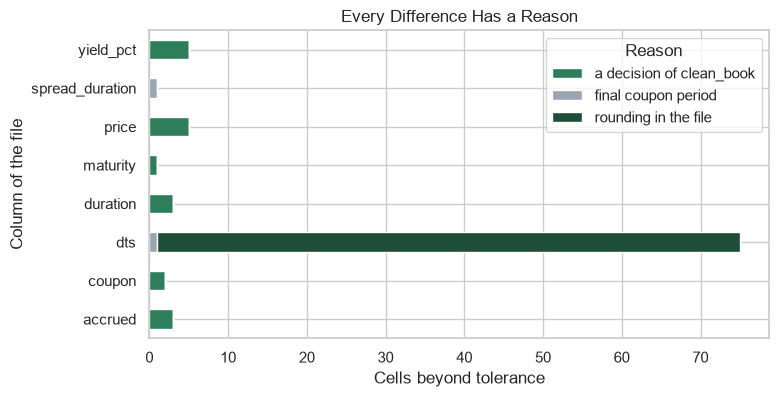

In [52]:
# written for you: each column's differences, split by reason (Course 1's Trade Blotter crosstab)
if reconciliation is ...:
    print('Chart: not attempted yet')
else:
    by_reason = pd.crosstab(reconciliation['column'], reconciliation['reason'])
    fig, ax = plt.subplots(figsize=(8, 4))
    by_reason.plot.barh(stacked=True, ax=ax)
    ax.set_title('Every Difference Has a Reason')
    ax.set_xlabel('Cells beyond tolerance')
    ax.set_ylabel('Column of the file')
    ax.legend(title='Reason')
    plt.show()

`dts` is the long bar, almost all rounding; every other bar is a decision, apart from the final-period bond's spread duration.

## 7 The Risk Report

### 7.1 `risk_report`

In [53]:
%%writefile -a capstone.py


# the positions sheet's columns, in order
POSITION_COLUMNS = ['cusip', 'ticker', 'issuer', 'sector', 'rating', 'bucket', 'grade', 'coupon',
                    'maturity', 'par_held', 'price', 'accrued', 'yield_pct', 'market_value',
                    'weight_pct', 'duration_calc', 'dv01', 'dv01_dollars', 'convexity', 'spread_bp',
                    'spread_duration_calc', 'dts_calc', 'dts_contribution']


def summary_line(group, name, rows):
    """One line of the summary: counts and sums, and averages weighted by market value."""
    weights = list(rows['market_value'])
    return {'group': group, 'name': name, 'bonds': len(rows),
            'market_value': rows['market_value'].sum(), 'weight_pct': rows['weight_pct'].sum(),
            'dv01_dollars': rows['dv01_dollars'].sum(),
            'duration': bondmath.weighted_average(list(rows['duration_calc']), weights),
            'spread_bp': bondmath.weighted_average(list(rows['spread_bp']), weights),
            'dts': bondmath.weighted_average(list(rows['dts_calc']), weights)}


def risk_report(book, ratings):
    """The three tables of a risk report, for a book clean_book returned.

    ratings is the rating scale (rating, bucket, grade). Returns a dict of three DataFrames:
      positions: one row per bond, with its weight in percent, DV01 in dollars, DTS contribution
      summary: the book, then each sector, then each rating bucket in credit order
      scenarios: rates -100, -25, +25, +100 bp, spreads +10 percent and +25 bp, each repriced in
                 full with dirty_price and estimated with price_change_estimate, in dollars
    A scenario is a mechanical what-if: every yield moves at once, settlement does not.
    """
    positions = book.merge(ratings[['rating', 'bucket', 'grade']], on='rating', how='left',
                           validate='many_to_one')
    assert positions['bucket'].notna().all(), 'a rating is not on the scale'
    positions['weight_pct'] = positions['market_value'] / positions['market_value'].sum() * 100
    positions['dv01_dollars'] = positions['dv01'] * positions['par_held'] / 100
    positions['dts_contribution'] = positions['weight_pct'] / 100 * positions['dts_calc']

    lines = [summary_line('book', 'all bonds', positions)]
    for sector in sorted(positions['sector'].unique()):
        lines.append(summary_line('sector', sector, positions[positions['sector'] == sector]))
    for bucket in ratings['bucket'].unique():
        rows = positions[positions['bucket'] == bucket]
        if len(rows) > 0:
            lines.append(summary_line('rating bucket', bucket, rows))

    # each scenario is a shift in bp for every bond
    count = len(positions)
    shifts = {}
    for shift in [-100, -25, 25, 100]:
        shifts[f'rates {shift:+d} bp'] = [shift] * count
    shifts['spreads +10 percent'] = list(positions['spread_bp'] * 10 / 100)
    shifts['spreads +25 bp'] = [25] * count
    settlements = [date.fromisoformat(text) for text in positions['as_of_date']]
    maturities = [date.fromisoformat(text) for text in positions['maturity']]
    bonds = list(zip(settlements, maturities, positions['coupon'], positions['yield_pct']))
    scenarios = []
    for name, shift_bp in shifts.items():
        after = pd.Series([bondmath.dirty_price(s, m, c, y + b / 100)
                           for (s, m, c, y), b in zip(bonds, shift_bp)])
        full = (positions['par_held'] * (after - positions['dirty_price']) / 100).sum()
        estimate = sum([bondmath.price_change_estimate(p, d, x, b) * f / 100 for p, d, x, b, f
                        in zip(positions['dirty_price'], positions['duration_calc'],
                               positions['convexity'], shift_bp, positions['par_held'])])
        scenarios.append({'scenario': name, 'full_reprice_dollars': full,
                          'estimate_dollars': estimate, 'estimate_less_full_dollars': estimate - full})
    return {'positions': positions[POSITION_COLUMNS], 'summary': pd.DataFrame(lines),
            'scenarios': pd.DataFrame(scenarios)}

Appending to capstone.py


In [54]:
importlib.reload(capstone)
report = capstone.risk_report(cleaned, ratings)
summary = report['summary']
book_line = summary.iloc[0]
answer_7_1 = book_line['duration']
summary.round(2)

,group,name,bonds,market_value,weight_pct,dv01_dollars,duration,spread_bp,dts
0,book,all bonds,199,496372835.0,100.00,295051.78,5.94,179.96,1019.56
1,sector,Consumer,27,60365187.5,12.16,41482.72,6.87,177.50,1134.77
2,sector,Energy,17,41873890.0,8.44,23674.47,5.65,189.39,1048.86
3,sector,Financials,24,61027597.5,12.29,38443.48,6.30,186.84,1052.73
4,sector,Health Care,18,35038005.0,7.06,17168.78,4.90,140.11,665.08
5,sector,Industrials,23,60331667.5,12.15,38244.65,6.34,216.35,1410.50
6,sector,Materials,26,69269215.0,13.96,35656.51,5.15,180.02,851.00
7,sector,Technology,11,30085330.0,6.06,15425.07,5.13,227.54,831.56
8,sector,Telecom,23,64872470.0,13.07,36735.55,5.66,167.90,1000.98
9,sector,Transportation,16,39410312.5,7.94,29269.51,7.43,134.31,959.08


In [55]:
check('Question 7.1', answer_7_1, 'e018a375dff5', places=3)

Question 7.1: correct


The book: 199 bonds, duration 5.944 years, spread 179.96 bp, DTS 1,019.56, and DV01 295,051.78 dollars, 4.5's figure.
Sectors follow in name order, then buckets in the rating scale's credit order.

### 7.2 By Sector and Rating

In [56]:
positions = report['positions']
# each sector's and each grade's share of the book's DTS, beside its share of value
dts_share = positions.groupby('sector')['dts_contribution'].sum() / book_line['dts'] * 100
value_share = positions.groupby('sector')['weight_pct'].sum()
grade_dts = positions.groupby('grade')['dts_contribution'].sum() / book_line['dts'] * 100
grade_value = positions.groupby('grade')['weight_pct'].sum()
answer_7_2a = dts_share.idxmax()
answer_7_2b = grade_dts['High Yield']
print(f"High Yield: {grade_value['High Yield']:.2f} percent of value, {answer_7_2b:.2f} of DTS")
pd.DataFrame({'value_pct': value_share, 'dts_pct': dts_share}).sort_values('dts_pct').round(2)

High Yield: 34.60 percent of value, 57.82 of DTS


,value_pct,dts_pct
sector,,
Health Care,7.06,4.60
Technology,6.06,4.94
Utilities,6.87,6.78
Transportation,7.94,7.47
Energy,8.44,8.68
Materials,13.96,11.65
Financials,12.29,12.69
Telecom,13.07,12.83
Consumer,12.16,13.54


In [57]:
check('Question 7.2 sector', answer_7_2a, '265dd381315b')
check('Question 7.2 High Yield', answer_7_2b, '8081778f49af', places=2)

Question 7.2 sector: correct
Question 7.2 High Yield: correct


Industrials carries the most DTS, 16.81 percent on 12.15 percent of value; Materials is the largest by value, 13.96 percent, with 11.65 of the DTS.
High Yield is 34.60 percent of value and 57.82 percent of DTS: spread risk sits where spreads are wide.

### 7.3 The What-Ifs

In [58]:
scenarios = report['scenarios'].set_index('scenario')
answer_7_3a = scenarios.loc['rates +100 bp', 'full_reprice_dollars']
answer_7_3b = scenarios.loc['rates -100 bp', 'estimate_less_full_dollars']
scenarios.round(2)

,full_reprice_dollars,estimate_dollars,estimate_less_full_dollars
scenario,,,
rates -100 bp,31068364.64,30994212.77,-74151.87
rates -25 bp,7470494.57,7469359.08,-1135.49
rates +25 bp,-7284340.84,-7283229.68,1111.16
rates +100 bp,-28083803.80,-28016142.26,67661.54
spreads +10 percent,-4993626.04,-4992529.50,1096.54
spreads +25 bp,-7284340.84,-7283229.68,1111.16


In [59]:
check('Question 7.3 up 100', answer_7_3a, 'fe48762b453d', places=2)
check('Question 7.3 estimate gap', answer_7_3b, '788a5e108373', places=2)

Question 7.3 up 100: correct
Question 7.3 estimate gap: correct


Every yield 100 bp higher takes 28,083,803.80 dollars off the book; 100 bp lower adds 31,068,364.64, more than the rise takes: convexity.
At 25 bp the estimate is within 1,135.49 dollars of the full reprice; at -100 bp it is 74,151.87 short, since it stops at the squared term.
Spreads +25 bp equals rates +25 bp: for a bullet, a spread move is a yield move.

### 7.4 The Workbook

In [60]:
# Course 1's ExcelWriter: one sheet per table, in the work folder
with pd.ExcelWriter('course2_risk_report.xlsx') as writer:
    for name, table in report.items():
        table.to_excel(writer, sheet_name=name, index=False)
# sheet_name=None reads every sheet into a dict; dtype keeps the CUSIP as text
back = pd.read_excel('course2_risk_report.xlsx', sheet_name=None, dtype={'cusip': str})
sheet = back['positions']
assert abs(sheet['dv01_dollars'].sum() - book_line['dv01_dollars']) < 1e-6, 'DV01 is off'
assert round(sheet['market_value'].sum(), 2) == expected_value, 'value is off'
answer_7_4a = list(back.keys())
answer_7_4b = len(sheet)
print(answer_7_4a, sheet.shape)

['positions', 'summary', 'scenarios'] (199, 23)


In [61]:
check('Question 7.4 sheets', answer_7_4a, 'd2c365e514fc')
check('Question 7.4 positions rows', answer_7_4b, 'a5a733724748', places=0)

Question 7.4 sheets: correct
Question 7.4 positions rows: correct


Three sheets came back, `positions` with 199 rows and 23 columns, adding to the book's DV01 and the note's value.
In Excel, `=SUM(R2:R200)` and the two `SUMPRODUCT` formulas return 295,051.78, 5.944, and 1,019.565, the summary's book line within 1.7e-10.

### 7.5 Commit the Code, Not the Workbook

In [62]:
!git -C "{work}" status --short
!git -C "{work}" diff --stat

 M capstone.py
?? course2_risk_report.xlsx
 capstone.py | 67 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 1 file changed, 67 insertions(+)


In [63]:
!git -C "{work}" add capstone.py
!git -C "{work}" commit -q -m "Capstone: risk_report and its three tables"
!git -C "{work}" status --short

?? course2_risk_report.xlsx


`git diff --stat` counts the 67 lines `risk_report` added; after the commit only the workbook is untracked, as notebook 14 left its grid.

## 8 Rerun, Do Not Redo

### 8.1 September Through Both Functions

In [64]:
september_clean = capstone.clean_book(september, benchmark, curve)
september_report = capstone.risk_report(september_clean, ratings)
september_line = september_report['summary'].iloc[0]
answer_8_1 = september_line['dv01_dollars']
# no decision changed a row: the delivered columns come back as they went in
print(september_clean[september.columns].equals(september), f'{answer_8_1:,.2f}')

True 306,996.11


In [65]:
check('Question 8.1', answer_8_1, '47a4c88c7496', places=2)

Question 8.1: correct


Every assert passed on September, settled on its own 2026-09-30, and no decision changed a row: the function holds rules, not November's fixes.
September's book DV01 is 306,996.11 dollars, notebook 14's figure.

### 8.2 A Test for Each Promise

In [66]:
%%writefile test_capstone.py
"""Tests for capstone.py: clean_book against the cover note, and on a clean month."""
from pathlib import Path

import pandas as pd

import capstone

HERE = Path(__file__).parent
BENCHMARK = pd.read_csv(HERE / 'benchmark.csv')
CURVE = pd.read_csv(HERE / 'course2_treasury_curve.csv')


def test_clean_book_ties_to_the_cover_note():
    raw = pd.read_csv(HERE / 'course2_capstone_holdings.csv')
    cleaned = capstone.clean_book(raw, BENCHMARK, CURVE)
    assert len(cleaned) == 199
    assert cleaned['par_held'].sum() == 493_000_000
    assert round(cleaned['market_value'].sum(), 2) == 496_372_835.00


def test_clean_book_leaves_september_alone():
    september = pd.read_csv(HERE / 'holdings.csv')
    cleaned = capstone.clean_book(september, BENCHMARK, CURVE)
    assert cleaned[september.columns].equals(september)

Writing test_capstone.py


In [67]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........................................                               [100%]
42 passed in 0.50s



In [68]:
# pytest's last line: re.search finds the number before 'passed'
answer_8_2 = int(re.search(r'(\d+) passed', result.stdout).group(1))
!git -C "{work}" add test_capstone.py
!git -C "{work}" commit -q -m "Capstone: two tests of clean_book"
print(answer_8_2)

42


In [69]:
check('Question 8.2', answer_8_2, '33b7a3db9e2f', places=0)

Question 8.2: correct


42 passed: the module's 40 and the two new tests, part of every later run.

### 8.3 Two Months Side by Side

In [70]:
figures = ['bonds', 'market_value', 'dv01_dollars', 'duration', 'spread_bp', 'dts']
comparison = pd.DataFrame({'September': september_line[figures], 'November': book_line[figures]})
# the summary's lines mix text and numbers; astype(float) makes these figures numbers again
comparison = comparison.astype(float)
comparison['change'] = comparison['November'] - comparison['September']
answer_8_3 = comparison.loc['dts', 'change']
# .T turns the table, so each figure is a column with its own decimals
comparison.T.round(2)

,bonds,market_value,dv01_dollars,duration,spread_bp,dts
September,200.0,490819215.0,306996.11,6.25,180.46,1064.11
November,199.0,496372835.0,295051.78,5.94,179.96,1019.56
change,-1.0,5553620.0,-11944.34,-0.31,-0.50,-44.55


In [71]:
check('Question 8.3', answer_8_3, 'a7688f7ee362', places=1)

Question 8.3: correct


From September to November the book went from 200 to 199 bonds and gained 5,553,620.00 dollars of value; DV01 fell 11,944.34 dollars, duration 0.31 years, and DTS 44.55.
The table describes the change; it does not split it into trades, two months less to maturity, and spread moves.

### The Change in Percent

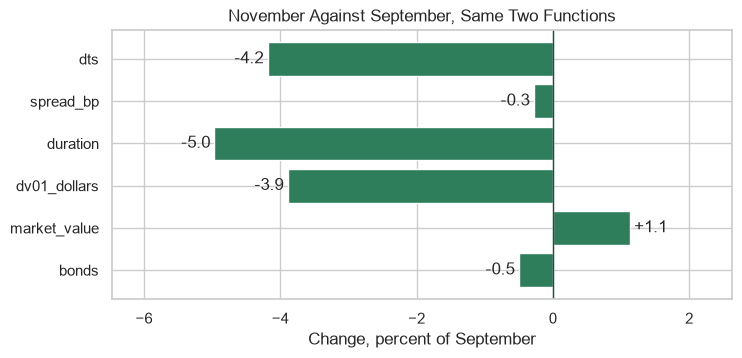

In [72]:
# written for you: each figure's change in percent of September, signed, as in notebook 14
if comparison is ...:
    print('Chart: not attempted yet')
else:
    change_pct = (comparison['November'] / comparison['September'] - 1) * 100
    fig, ax = plt.subplots(figsize=(8, 3.5))
    bars = ax.barh(change_pct.index, change_pct)
    ax.axvline(0, color='#1E4D3A', linewidth=1)
    ax.bar_label(bars, fmt='{:+.1f}', padding=3)
    # room on both sides for the labels
    ax.set_xlim(change_pct.min() - 1.5, change_pct.max() + 1.5)
    ax.set_title('November Against September, Same Two Functions')
    ax.set_xlabel('Change, percent of September')
    plt.show()

Duration fell most, 5.0 percent, then DTS 4.2 and DV01 3.9, while value rose 1.1 percent.

## 9 The Deliverables

### 9.1 The AI Check

The assistant passed `'ACT/ACT'` to `accrued_interest`, where the docstring and the cover note say 30/360: a plausible number, wrong for this book.
The fixed function changes that one argument.

**Excel side by side.** The month-end bond in desktop Excel for Windows, tested.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Accrued, 30/360, basis 0</td><td align="left"><code>accrued_interest(..., 2, '30/360')</code></td><td align="left"><code>=100*5.5/100/2*COUPDAYBS(DATE(2026,11,30),DATE(2033,8,31),2,0)/COUPDAYS(DATE(2026,11,30),DATE(2033,8,31),2,0)</code></td><td align="left">1.375</td></tr>
<tr><td align="left">Accrued, actual/actual, basis 1: the assistant's</td><td align="left"><code>accrued_interest(..., 2, 'ACT/ACT')</code></td><td align="left"><code>=100*5.5/100/2*COUPDAYBS(DATE(2026,11,30),DATE(2033,8,31),2,1)/(COUPNCD(DATE(2026,11,30),DATE(2033,8,31),2,1)-COUPPCD(DATE(2026,11,30),DATE(2033,8,31),2,1))</code></td><td align="left">1.382596685082873</td></tr>
</table>
<br clear="left">

In [73]:
def recompute_accrued(book):
    """Accrued interest per 100 of face for every bond in a month-end book.

    book has as_of_date and maturity (text, year-month-day) and coupon (percent a year).
    Settlement is each row's as_of_date. Convention: the book's own, as the cover note states:
    semiannual coupons on US 30/360. Returns a pandas Series of floats in the book's order.
    """
    settlements = [date.fromisoformat(text) for text in book['as_of_date']]
    maturities = [date.fromisoformat(text) for text in book['maturity']]
    # the fix: the book's convention, 30/360, where the assistant wrote 'ACT/ACT'
    accrued = [bondmath.accrued_interest(s, m, c, 2, '30/360')
               for s, m, c in zip(settlements, maturities, book['coupon'])]
    return pd.Series(accrued, index=book.index)

In [74]:
# the month-end bond's three terms, typed in
month_end_bond = pd.DataFrame({'as_of_date': ['2026-11-30'], 'maturity': ['2033-08-31'],
                               'coupon': [5.5]})
recompute_accrued(month_end_bond)

0    1.375
dtype: float64

In [75]:
# Excel's accrued for the holdings rows of the reference file, settled 2026-09-30 on 30/360
reference = pd.read_csv('bondmath_excel_reference.csv')
excel_rows = reference[reference['group'] == 'holdings']
test_book = pd.DataFrame({'as_of_date': excel_rows['settlement'],
                          'maturity': excel_rows['maturity'], 'coupon': excel_rows['coupon_pct']})
gap = (recompute_accrued(test_book) - excel_rows['accrued']).abs()
assert gap.max() < 1e-9, (f"{(gap >= 1e-9).sum()} rows differ from Excel's accrued; "
                          f"the largest gap is {gap.max():.6f}")
print(f"All {len(gap)} rows match Excel's accrued within 1e-9")

All 200 rows match Excel's accrued within 1e-9


In [76]:
fixed = recompute_accrued(cleaned)
ai_month_end = fixed[cleaned['cusip'] == '99008IYA6'].iloc[0]
# the assistant's version, for comparison: the same step on actual/actual
wrong = pd.Series([bondmath.accrued_interest(s, m, c, 2, 'ACT/ACT')
                   for s, m, c in zip(settlements, maturities, cleaned['coupon'])])
ai_rows_changed = ((wrong - fixed).abs() > 1e-9).sum()
print(f'{ai_month_end:.6f}', f"{wrong[cleaned['cusip'] == '99008IYA6'].iloc[0]:.6f}",
      ai_rows_changed)

1.375000 1.382597 197


In [77]:
check('AI check month-end accrued', ai_month_end, '8c553b5f3a89', places=6)
check('AI check bonds affected', ai_rows_changed, 'bb8aaa24ce35', places=0)

AI check month-end accrued: correct
AI check bonds affected: correct


1.375000 for the month-end bond, 4.4's figure; the assistant's version gave 1.382597 and would have been wrong on 197 of 199 bonds.
No check of the file would catch it, since the file and the function would agree on the wrong number: a test against Excel's does.

### 9.2 The AI-Use Log

In [78]:
%%writefile ai_use_log.md
# AI-use log

A model log, written for this course to show the level of detail.

| What I asked | What I kept or rejected | How I checked it |
| --- | --- | --- |
| How to compare two tables column by column, each at its own tolerance | Kept a dict of tolerances and a loop over the columns; rejected `DataFrame.compare`, which has no tolerance | Ran both on two rows typed by hand, one gap inside the tolerance and one outside |
| A docstring for `clean_book` listing its decisions, given my code | Kept the numbered list; rejected a line saying accrued is "on ACT/ACT for accuracy", since the cover note says 30/360 | Read every line against the code, then ran pytest and the checkpoint |
| How to write three tables to one workbook, a sheet each | Kept `pd.ExcelWriter` with one `to_excel` per sheet and `index=False` | Read every sheet back and asserted the DV01 and the market value |

No row of the extract went into the assistant: each question described the columns and the task.

Writing ai_use_log.md


### 9.3 A Model Page

In [79]:
%%writefile description.md
# The book, 2026-11-30

All names are invented. Every figure is recomputed with `bondmath` from the cleaned extract.

**The book in numbers.** 199 bonds, 493.0 million dollars of face, and 496.37 million dollars of market value. Weighted by market value, modified duration is 5.94 years, the spread to the curve 179.96 bp, and DTS 1,019.56 years times bp. DV01 is 295,051.78 dollars per basis point.

**Where the risk sits.** The largest sectors by market value are Materials (13.96 percent), Telecom (13.07), and Financials (12.29). Industrials carries the most DTS, 16.81 percent of the book's on 12.15 percent of its value. High Yield is 34.60 percent of market value and 57.82 percent of DTS; Investment Grade is 65.40 percent of value and 42.18 percent of DTS.

**Under each what-if.** These are instantaneous what-ifs, not forecasts. With every yield 100 bp higher the book's value changes by -28,083,803.80 dollars (-5.66 percent), and 100 bp lower by +31,068,364.64 (+6.26 percent). For 25 bp the changes are -7,284,340.84 and +7,470,494.57 dollars. Every spread 10 percent wider changes it by -4,993,626.04 dollars, and every spread 25 bp wider by -7,284,340.84, the same as a 25 bp rise in yields. The duration and convexity estimate is within 1,135.49 dollars of the full reprice at 25 bp and 74,151.87 dollars short at -100 bp.

**September and November.** On the same two functions the book went from 200 to 199 bonds and from 490.82 to 496.37 million dollars of value; DV01 fell from 306,996.11 to 295,051.78 dollars, duration from 6.25 to 5.94 years, and DTS from 1,064.11 to 1,019.56.

**The data.** The extract had 201 rows against 199 bonds in the cover note. Found and fixed: 2 exact copies, removed; 1 maturity ten years early, replaced with the benchmark's; 2 coupons and 3 yields entered as decimals, multiplied by 100; 2 blank prices and 2 blank yields, solved from the other number of the pair; 3 accrued figures on actual/360, replaced with 30/360; 3 dirty prices in the clean price column, replaced with price less accrued; 3 Macaulay durations, replaced with modified. The cleaned book matches all three control totals to the cent. CUSIPs, ratings, sizes, price dates, and every `oas` were checked and found clean. Of 95 cells beyond tolerance, 19 are these fixes, 74 are DTS rounding in the file, and 2 are the final-period convention of one bond; none is unexplained.

**Open items.** Operations to confirm the 19 corrected bonds and to say why 2 rows were sent twice.

Writing description.md


In [80]:
!git -C "{work}" add ai_use_log.md description.md
!git -C "{work}" commit -q -m "Capstone: the AI-use log and the page"
!git -C "{work}" tag course2
history = !git -C "{work}" log --oneline --decorate
answer_git = len(history)
print(answer_git)
print('\n'.join(history[:5]))

18
a4a5c7d (HEAD -> main, tag: course2) Capstone: the AI-use log and the page
50d1a70 Capstone: two tests of clean_book
c373bd2 Capstone: risk_report and its three tables
7d0fb06 Capstone: clean_book and its seven decisions
9574fac Notebook 14: weighted_average and price_change_estimate


In [81]:
check('Question Git', answer_git, 'fb93dc72986c', places=0)

Question Git: correct


18 commits: the 14 `start_day` made and the capstone's 4, with `course2` on the last, as `week1` and `week2` mark the weeks.

## The Report to the Desk

The seven decisions are `clean_book`'s, and the last two rows are kept as delivered.

The planted problems are listed in `data/course2_capstone_answer_key.md`, and they match.

<table align="left">
<tr><th align="left">#</th><th align="left">Finding</th><th align="left">How it was found</th><th align="left">Rows</th><th align="left">What was done</th><th align="left">Effect</th></tr>
<tr><td align="left">1</td><td align="left">Rows sent twice</td><td align="left">the totals, <code>duplicated()</code></td><td align="left">2</td><td align="left">removed the copies</td><td align="left">the three control totals tie</td></tr>
<tr><td align="left">2</td><td align="left">Maturity before the as-of date</td><td align="left">rule 2</td><td align="left">1</td><td align="left">the benchmark's maturity</td><td align="left">2031-07-10, ten years later</td></tr>
<tr><td align="left">3</td><td align="left">Coupons and yields as decimals</td><td align="left">rule 4</td><td align="left">5</td><td align="left">times 100</td><td align="left">mean yield 6.010 to 6.092 percent</td></tr>
<tr><td align="left">4</td><td align="left">Blank prices and yields</td><td align="left">rule 3</td><td align="left">4</td><td align="left">solved from the other of the pair</td><td align="left">no blank cell</td></tr>
<tr><td align="left">5</td><td align="left">Accrued on actual/360</td><td align="left"><code>accrued_interest</code></td><td align="left">3</td><td align="left">the 30/360 accrued</td><td align="left">every accrued reproduces</td></tr>
<tr><td align="left">6</td><td align="left">Dirty price in the price column</td><td align="left"><code>price</code></td><td align="left">3</td><td align="left">price less accrued</td><td align="left">every row ties out to the cent</td></tr>
<tr><td align="left">7</td><td align="left">Macaulay duration in the duration column</td><td align="left"><code>modified_duration</code></td><td align="left">3</td><td align="left">modified duration</td><td align="left">duration equals spread duration</td></tr>
<tr><td align="left">-</td><td align="left">DTS from a rounded spread duration</td><td align="left"><code>dts</code></td><td align="left">74</td><td align="left">kept</td><td align="left">rounding in the file</td></tr>
<tr><td align="left">-</td><td align="left">The final-period bond's spread duration and DTS</td><td align="left"><code>spread_duration</code></td><td align="left">1</td><td align="left">kept</td><td align="left">the final-period convention</td></tr>
</table>
<br clear="left">

Checked and found clean: CUSIPs, ratings, sizes, price dates, and every `oas`, which reproduces on the formula curve within 1e-9 bp.

[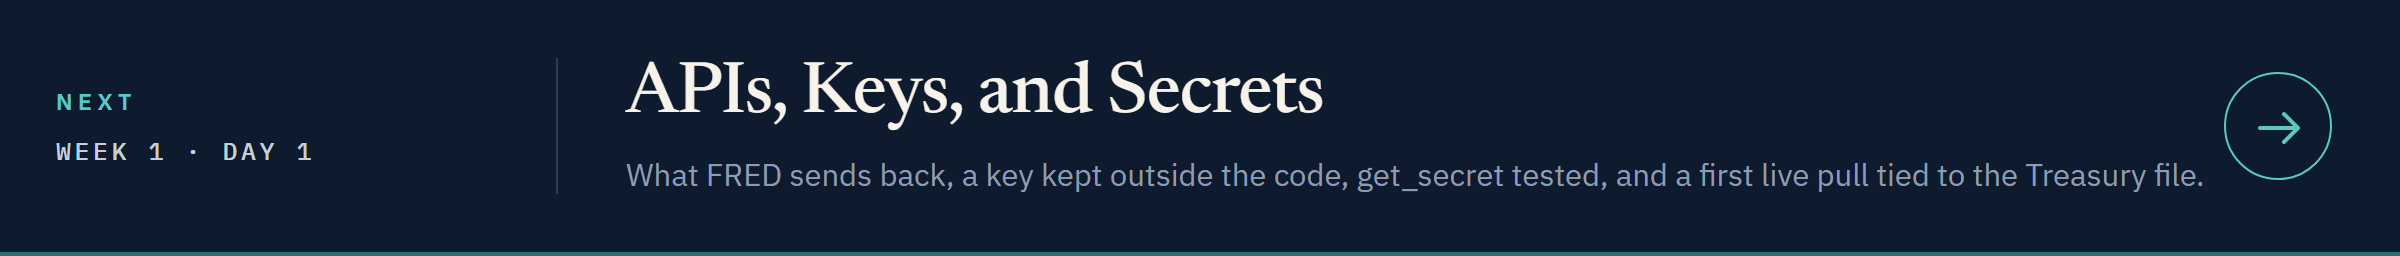](../../../course03_market_data/week1/day1/01_apis_keys_and_secrets.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day1/01_apis_keys_and_secrets.ipynb)